## Importing the libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

## a. Exploratory Data Analysis (EDA)
- **Number of records and attributes**: ข้อมูลตั้งต้นมีลูกค้า 5,000 คน และ 480 คน (9.6%) ยอมรับข้อเสนอสินเชื่อ[cite: 3] หลังจากตัดตัวแปร ID และ ZIP Code ออก จะเหลือ 12 Attributes
- **Distribution of Personal Loan**: เป็น Imbalanced Dataset เนื่องจาก Class 0 (ไม่รับสินเชื่อ) มีจำนวนมากกว่า Class 1 (รับสินเชื่อ) อย่างมาก (ประมาณ 90% ต่อ 10%)
- **Data-quality issues**: พบว่ามีค่าติดลบในคอลัมน์ `Experience` ซึ่งไม่สมเหตุสมผลในความเป็นจริง

## Pre-process the dataset and Reading the dataset

In [2]:
df = pd.read_csv("bank_dataset.csv")
df = df.drop(columns=['ID','ZIP Code'])  # 1. Remove ID and ZIP Code.
with pd.option_context('display.max_rows', 10): display(df)


,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,4,1.6,1,0,0,1,0,0,0
1,45,19,34,3,1.5,1,0,0,1,0,0,0
2,39,15,11,1,1.0,1,0,0,0,0,0,0
3,35,9,100,1,2.7,2,0,0,0,0,0,0
4,35,8,45,4,1.0,2,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,29,3,40,1,1.9,3,0,0,0,0,1,0
4996,30,4,15,4,0.4,1,85,0,0,0,1,0
4997,63,39,24,2,0.3,3,0,0,0,0,0,0
4998,65,40,49,3,0.5,2,0,0,0,0,1,0


In [3]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]

print("Numerical  :", num_cols)
print("Categorical:", cat_cols)

desc = pd.DataFrame({
    "count":  df[num_cols].count(),
    "mean":   df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode":   df[num_cols].mode().iloc[0],
    "std":    df[num_cols].std(),
    "var":    df[num_cols].var(),
    "min":    df[num_cols].min(),
    "max":    df[num_cols].max(),
    "skew":   df[num_cols].skew(),
    "kurtosis": df[num_cols].kurtosis(),
})

desc["cv"] = desc["std"] / desc["mean"]
desc.round(3)

Numerical  : ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Education', 'Mortgage', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
Categorical: []


,count,mean,median,mode,std,var,min,max,skew,kurtosis,cv
Age,5000,45.338,45.0,35.0,11.463,131.404,23.0,67.0,-0.029,-1.153,0.253
Experience,5000,20.105,20.0,32.0,11.468,131.514,-3.0,43.0,-0.026,-1.122,0.570
Income,5000,73.774,64.0,44.0,46.034,2119.104,8.0,224.0,0.841,-0.044,0.624
Family,5000,2.396,2.0,1.0,1.148,1.317,1.0,4.0,0.155,-1.404,0.479
CCAvg,5000,1.938,1.5,0.3,1.748,3.054,0.0,10.0,1.598,2.647,0.902
Education,5000,1.881,2.0,1.0,0.840,0.705,1.0,3.0,0.227,-1.546,0.447
Mortgage,5000,56.499,0.0,0.0,101.714,10345.698,0.0,635.0,2.104,4.757,1.800
Personal Loan,5000,0.096,0.0,0.0,0.295,0.087,0.0,1.0,2.744,5.530,3.069
Securities Account,5000,0.104,0.0,0.0,0.306,0.094,0.0,1.0,2.588,4.701,2.929
CD Account,5000,0.060,0.0,0.0,0.238,0.057,0.0,1.0,3.692,11.633,3.945


In [4]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "kind": ["Numerical" if c in num_cols else "Categorical" for c in df.columns],
    "n_unique": df.nunique(),
})

audit

,dtype,kind,n_unique
Age,int64,Numerical,45
Experience,int64,Numerical,47
Income,int64,Numerical,162
Family,int64,Numerical,4
CCAvg,float64,Numerical,108
Education,int64,Numerical,3
Mortgage,int64,Numerical,347
Personal Loan,int64,Numerical,2
Securities Account,int64,Numerical,2
CD Account,int64,Numerical,2


In [5]:
# 2. Remove records where Experience < 0.
df.drop(df[df['Experience'] < 0].index, inplace=True)


In [6]:
sentinel = "?"
miss = pd.DataFrame({
    "n_missing": {c: int((df[c].astype(str).str.strip() == sentinel).sum()) for c in num_cols}
})

miss

,n_missing
Age,0
Experience,0
Income,0
Family,0
CCAvg,0
Education,0
Mortgage,0
Personal Loan,0
Securities Account,0
CD Account,0


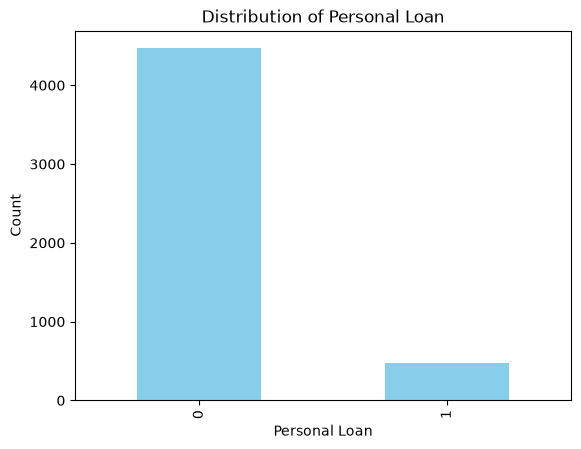

In [7]:
fig, ax = plt.subplots()

df['Personal Loan'].value_counts().plot(kind='bar', color='skyblue')
plt.ylabel('Count')
plt.xlabel('Personal Loan')
plt.title('Distribution of Personal Loan')

plt.show()

## b. Data Pre-processing (Continued)

In [8]:
# 4. Convert Education into appropriate dummy/binary variables.
df = pd.get_dummies(df, columns=['Education'], drop_first=False, dtype=int)

# 3. Use Personal Loan as the target/class label.
X = df.drop(columns=['Personal Loan'])
y = df['Personal Loan']

In [9]:
# Partition the cleaned dataset into Training set: 60%, Validation set: 40%
# random_state = 1992 (ตามเงื่อนไขข้อ d)
RANDOM_STATE = 1992
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.40, random_state=RANDOM_STATE)

# 5. Standardize the predictor variables using Z-score standardization.
# เรียนรู้ (fit) พารามิเตอร์จาก Training set เท่านั้น แล้ว apply ไปยัง Validation set
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## c. k-NN with k=3
ทำนายลูกค้าใหม่โดยใช้ k=3, Euclidean distance, unweighted voting

In [10]:
knn_3 = KNeighborsClassifier(n_neighbors=3, weights='uniform', metric='euclidean')
knn_3.fit(X_train_scaled, y_train)

# สร้างข้อมูลลูกค้าใหม่ตามตารางที่ให้มา
# Education 2 = 1, Education 3 = 0 หมายความว่า Education_1 = 0, Education_2 = 1, Education_3 = 0
new_customer = pd.DataFrame([{
    'Age': 40, 'Experience': 10, 'Income': 84, 'Family': 2, 'CCAvg': 2, 'Mortgage': 0, 
    'Securities Account': 0, 'CD Account': 0, 'Online': 1, 'CreditCard': 1,
    'Education_1': 0, 'Education_2': 1, 'Education_3': 0
}], columns=X_train.columns)

new_customer_scaled = scaler.transform(new_customer)
pred_3 = knn_3.predict(new_customer_scaled)
print(f"Predicted Personal Loan (k=3): {pred_3[0]}")

Predicted Personal Loan (k=3): 0


## d. Find an Appropriate Value of k
Train k-NN models using k=1, 2, ..., 10

In [11]:
k_values_1_to_10 = range(1, 11)
val_accuracies = []

print("k\tAccuracy")
for k in k_values_1_to_10:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred_val = knn.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_val)
    val_accuracies.append(acc)
    print(f"{k}\t{acc:.4f}")

k	Accuracy
1	0.9571
2	0.9485
3	0.9586
4	0.9449
5	0.9520
6	0.9455
7	0.9495
8	0.9444
9	0.9465
10	0.9444


## e. Select Your Best Model

In [12]:
best_idx = np.argmax(val_accuracies)
best_k_val = k_values_1_to_10[best_idx]
best_acc_val = val_accuracies[best_idx]

print(f"Best k: {best_k_val}")
print(f"Validation accuracy: {best_acc_val:.4f}")

# Train using the best k to plot confusion matrix
knn_best = KNeighborsClassifier(n_neighbors=best_k_val)
knn_best.fit(X_train_scaled, y_train)
y_pred_best = knn_best.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred_best)
cm_df = pd.DataFrame(cm, index=['Actual 0', 'Actual 1'], columns=['Predicted 0', 'Predicted 1'])
print("\nConfusion matrix for the validation data:")
display(cm_df)

Best k: 3
Validation accuracy: 0.9586

Confusion matrix for the validation data:


,Predicted 0,Predicted 1
Actual 0,1781,6
Actual 1,76,117


**Why did you select this value of k?**
เหตุผลที่เลือกค่า k นี้เพราะให้ค่า Validation Accuracy สูงที่สุดเมื่อเทียบกับค่า k ตั้งแต่ 1 ถึง 10 ซึ่งหมายความว่าโมเดลมีความสามารถในการทั่วไป (Generalization) ในการทำนายข้อมูลที่ยังไม่เคยเห็นได้ดีที่สุด

## f. Predict the New Customer

In [13]:
pred_best_k = knn_best.predict(new_customer_scaled)
print(f"Predicted Personal Loan (with best k = {best_k_val}): {pred_best_k[0]}")
print(f"Compare to prediction with k=3: {pred_3[0]}")

Predicted Personal Loan (with best k = 3): 0
Compare to prediction with k=3: 0
